# 02. 처음 보는 약물 하나를 예측해 보기 (validation 약물, 재학습 없음)

서버의 unit 저장소와 동결된 checkpoint 하나를 쓴다. **시험(test) 약물의 정답은 열지 않는다.** 대신 개발용 validation 약물에서

1. 예측 함수가 받는 입력이 처리 전 RNA(X0)와 약물 지문뿐임을 확인하고,
2. 예측한 변화와 실제 변화를 나란히 그려 본다.

In [1]:
import os, json, sys
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
ROOT = os.environ.get("R4_ROOT", os.getcwd())
os.chdir(ROOT); sys.path.insert(0, ROOT)
pd.set_option("display.width", 200); pd.set_option("display.float_format", lambda v: f"{v:.4f}")
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8983"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
                     "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.edgecolor": "#8a8983", "font.size": 10,
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
MAN = "manifests/response_geometry_r4"
os.environ.setdefault("R4_PROC", os.path.join(ROOT, "assets/processed/units_v1"))
os.environ.setdefault("TB_PROC", "/mnt/S1/sdata/workbench/Virtual_Cell/gssong/vcell_liver_transigen_adaptation_b1/assets/processed/cmap2020_v1")
os.environ.setdefault("R4_WAVE", os.path.join(ROOT, "assets/external/WAVE"))
import torch, inspect
from src.response_geometry_r4.data import Store, TrainStats
from src.response_geometry_r4.models import W1DeltaAnchor
fr = json.load(open(f"{MAN}/freeze_manifest.json"))

In [2]:
print(inspect.signature(W1DeltaAnchor.predict_delta))   # (self, x0, fp): no treated profile, no teacher
S = Store(); st = TrainStats(S)
name = [k for k in fr["models"] if fr["models"][k][0]["arm"] in ("w1", "w2")]
print("frozen models with the W1/W2 architecture:", name)
r = fr["models"][name[-1]][0]
m = W1DeltaAnchor(); m.load_state_dict(torch.load(r["checkpoint"], map_location="cpu")); m.eval()
print("using", name[-1], r["run_id"])

(self, x0, fp)
frozen models with the W1/W2 architecture: ['W1_delta_anchor', 'W2_proposed', 'W2_before_mod1']
using W2_before_mod1 full_w2_lr1e-3_lam0.05_s42


In [3]:
u = S.units
val_jhh5 = S.val[u.cell.to_numpy()[S.val] == "JHH5"]
rms = np.sqrt((S.delta(val_jhh5) ** 2).mean(1))
pick = val_jhh5[np.argsort(-rms)[:1]]            # the validation drug with the largest measured JHH5 response
x0 = torch.from_numpy(S.x0[pick]); fp = torch.from_numpy(S.fp(pick))
pred = m.predict_delta(x0, fp).numpy()[0]; true = S.delta(pick)[0]
print(u.drug_group.iloc[pick[0]], "| RMSE", np.sqrt(((pred - true) ** 2).mean()).round(3), "| Pearson", np.corrcoef(pred, true)[0, 1].round(3),
      "| cell-mean-only RMSE", np.sqrt(((st.cell_mean[S.cell_idx[pick[0]]] - true) ** 2).mean()).round(3))

G:BRD-K99545815 | RMSE 1.295 | Pearson 0.708 | cell-mean-only RMSE 1.438


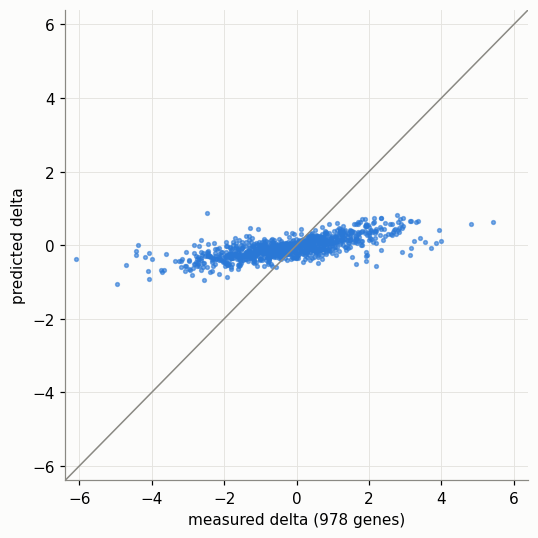

In [4]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(true, pred, s=6, color=BLUE, alpha=0.6)
lim = np.abs(np.r_[true, pred]).max() * 1.05
ax.plot([-lim, lim], [-lim, lim], color=GREY, lw=1); ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel("measured delta (978 genes)"); ax.set_ylabel("predicted delta")
plt.tight_layout(); plt.show()

예측 크기가 실제보다 작게 나오는 경향(점이 가로로 눕는 모양)은 이 과제에서 흔하다. 새 약물의 구조만으로는 강한 반응의 크기를 다 맞추기 어렵기 때문이다(가설; 이 노트북에서 검증하지 않음).